# Визуализация витрин успеваемости (дополнительное задание)

Вариант 4 «Студенты и успеваемость». Данные берутся из витрин `mart.student_performance`, `mart.group_stats`
и исходных таблиц схемы `raw`, которые создает DAG `student_performance_mart`.

1. Рейтинг студентов в группе
2. Распределение оценок по предметам
3. Динамика среднего балла по семестрам
4. Формы контроля (экзамен / зачёт)

In [1]:
# %pip install pandas matplotlib psycopg2-binary -q
import os
import pandas as pd
import psycopg2
import matplotlib.pyplot as plt

In [2]:
# Подключение к базе students_db из docker-compose (параметры STUDENTS_DB_* в .env)
DB = {
    "host": os.getenv("DB_HOST_LOCAL", "localhost"),
    "port": os.getenv("DB_PORT_LOCAL", "5435"),
    "dbname": os.getenv("DB_NAME_LOCAL", "students_db"),
    "user": os.getenv("DB_USER_LOCAL", "student"),
    "password": os.getenv("DB_PASSWORD_LOCAL", "student"),
}
GROUP_ID = 1          # группа для рейтинга студентов

def q(sql):
    with psycopg2.connect(**DB) as conn, conn.cursor() as cur:
        cur.execute(sql)
        return pd.DataFrame(cur.fetchall(), columns=[c.name for c in cur.description])

os.makedirs("images", exist_ok=True)

# Единый стиль графиков
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
BLUE, ORANGE, AQUA, YELLOW, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#c3c2b7"
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10, "axes.edgecolor": GRAY, "axes.labelcolor": "#52514e",
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
})

In [3]:
students = q('''
    SELECT sp.*, s.full_name, g.group_number
    FROM mart.student_performance sp
    JOIN raw.students s USING (student_id)
    JOIN raw.groups g   ON g.group_id = sp.group_id
''')
group_stats = q("SELECT gs.*, g.group_number FROM mart.group_stats gs JOIN raw.groups g USING (group_id) ORDER BY group_id")
grades = q('''
    SELECT gr.grade, gr.grade_date, sb.subject_name, sb.semester, sb.control_form,
           st.group_id, g.course
    FROM raw.grades gr
    JOIN raw.subjects sb USING (subject_id)
    JOIN raw.students st USING (student_id)
    JOIN raw.groups g    ON g.group_id = st.group_id
''')
subjects = q("SELECT * FROM raw.subjects")
print(f"Студентов: {len(students)}, групп: {len(group_stats)}, оценок: {len(grades)}, предметов: {len(subjects)}")
group_stats

Студентов: 250, групп: 10, оценок: 4466, предметов: 30


,group_id,course,institute,avg_grade_group,pass_rate,best_subject,worst_subject,group_number
0,1,1,Институт энергетики и автоматизированных систем,3.92,80.00,Линейная алгебра,Физика,АПИб-25-1
1,2,2,"Институт металлургии, машиностроения и материа...",4.21,88.00,Базы данных,Алгоритмы и структуры данных,МШб-24-1
2,3,3,"Институт строительства, архитектуры и искусства",4.06,64.00,Теория вероятностей и статистика,Операционные системы,СТб-23-1
3,4,4,Институт энергетики и автоматизированных систем,3.73,60.00,Базы данных,Операционные системы,ИВТб-22-1
4,5,1,"Институт металлургии, машиностроения и материа...",3.92,80.00,Программирование на Python,Физика,МШб-25-2
5,6,2,"Институт строительства, архитектуры и искусства",3.98,64.00,Физика,Базы данных,СТб-24-2
6,7,3,Институт энергетики и автоматизированных систем,3.92,72.00,Тестирование ПО,Компьютерные сети,ИВТб-23-2
7,8,4,"Институт металлургии, машиностроения и материа...",3.93,52.00,Web-технологии,Теория вероятностей и статистика,МШб-22-2
8,9,1,"Институт строительства, архитектуры и искусства",3.67,80.00,Линейная алгебра,Физика,АРб-25-3
9,10,2,Институт энергетики и автоматизированных систем,4.04,68.00,Алгоритмы и структуры данных,Теория вероятностей и статистика,ИВТб-24-3


## 1. Рейтинг студентов в группе

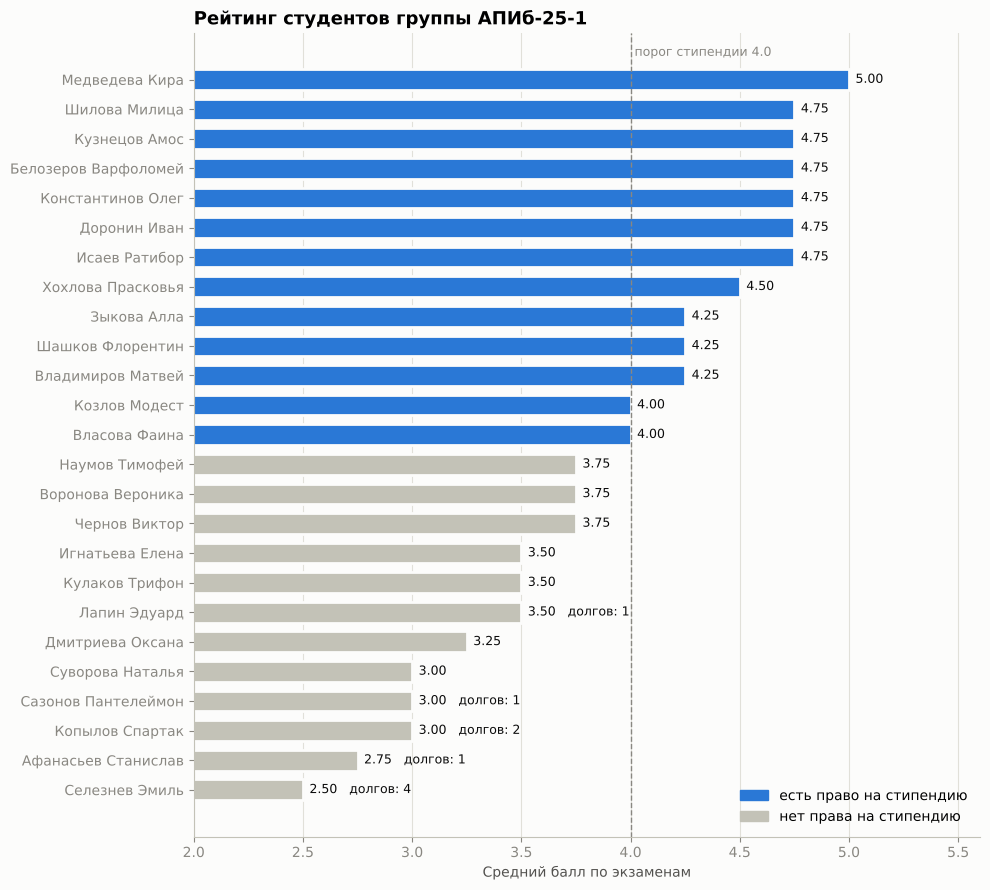

In [4]:
g = students[students.group_id == GROUP_ID].sort_values(["avg_grade", "total_credits"]).reset_index(drop=True)
g["label"] = g.full_name.str.split().str[:2].str.join(" ")
colors = [BLUE if s else GRAY for s in g.scholarship_eligible]

fig, ax = plt.subplots(figsize=(10, 9))
bars = ax.barh(g.label, g.avg_grade.astype(float), color=colors, height=0.7, edgecolor="#fcfcfb", linewidth=2)
for b, avg, debt in zip(bars, g.avg_grade, g.debt_count):
    txt = f"{avg:.2f}" + (f"   долгов: {debt}" if debt else "")
    ax.text(b.get_width() + 0.03, b.get_y() + b.get_height() / 2, txt, va="center", fontsize=9, color=INK)
ax.axvline(4.0, color=MUTED, lw=1, ls="--")
ax.text(4.0, len(g) - 0.3, " порог стипендии 4.0", color=MUTED, fontsize=9, va="bottom")
ax.set_xlim(2, 5.6)
ax.set_xlabel("Средний балл по экзаменам")
ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=GRAY)],
          labels=["есть право на стипендию", "нет права на стипендию"], loc="lower right", frameon=False)
ax.set_title(f"Рейтинг студентов группы {g.group_number.iloc[0]}")
plt.tight_layout(); plt.savefig("images/1_rating.png", dpi=120); plt.show()

## 2. Распределение оценок по предметам

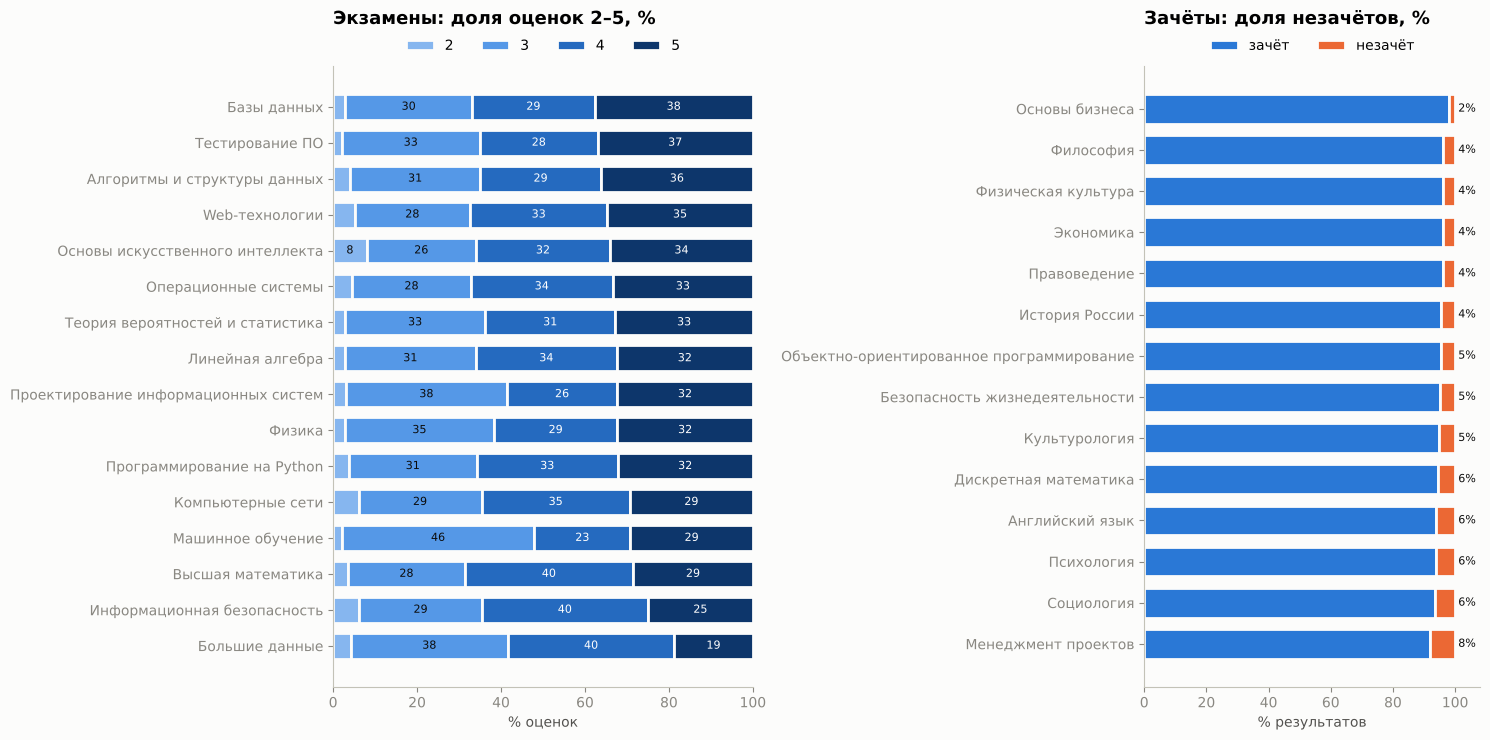

In [5]:
ex = grades[grades.control_form == "экзамен"]
dist = pd.crosstab(ex.subject_name, ex.grade.astype(int), normalize="index") * 100
dist = dist.reindex(columns=[2, 3, 4, 5], fill_value=0).sort_values([5, 4], ascending=True)
seq = {2: "#86b6ef", 3: "#5598e7", 4: "#256abf", 5: "#0d366b"}      # одна шкала: светлее = ниже оценка

zc = grades[grades.control_form == "зачёт"]
zdist = pd.crosstab(zc.subject_name, zc.grade, normalize="index") * 100
zdist = zdist.reindex(columns=["зачёт", "незачёт"], fill_value=0).sort_values("зачёт")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7.5), gridspec_kw={"width_ratios": [1.25, 1]})
left = pd.Series(0.0, index=dist.index)
for grade in [2, 3, 4, 5]:
    ax1.barh(dist.index, dist[grade], left=left, color=seq[grade], label=str(grade), height=0.72,
             edgecolor="#fcfcfb", linewidth=2)
    for y, (l, v) in enumerate(zip(left, dist[grade])):
        if v >= 7:
            ax1.text(l + v / 2, y, f"{v:.0f}", ha="center", va="center", fontsize=8,
                     color="white" if grade >= 4 else INK)
    left += dist[grade]
ax1.set_xlim(0, 100); ax1.set_xlabel("% оценок")
ax1.legend(ncol=4, title=None, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
ax1.set_title("Экзамены: доля оценок 2–5, %", pad=30)

ax2.barh(zdist.index, zdist["зачёт"], color=BLUE, label="зачёт", height=0.72, edgecolor="#fcfcfb", linewidth=2)
ax2.barh(zdist.index, zdist["незачёт"], left=zdist["зачёт"], color=ORANGE, label="незачёт", height=0.72,
         edgecolor="#fcfcfb", linewidth=2)
for y, v in enumerate(zdist["незачёт"]):
    ax2.text(101, y, f"{v:.0f}%", va="center", fontsize=8, color=INK)
ax2.set_xlim(0, 108); ax2.set_xlabel("% результатов")
ax2.legend(ncol=2, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
ax2.set_title("Зачёты: доля незачётов, %", pad=30)
plt.tight_layout(); plt.savefig("images/2_grades_by_subject.png", dpi=120); plt.show()

## 3. Динамика среднего балла по семестрам

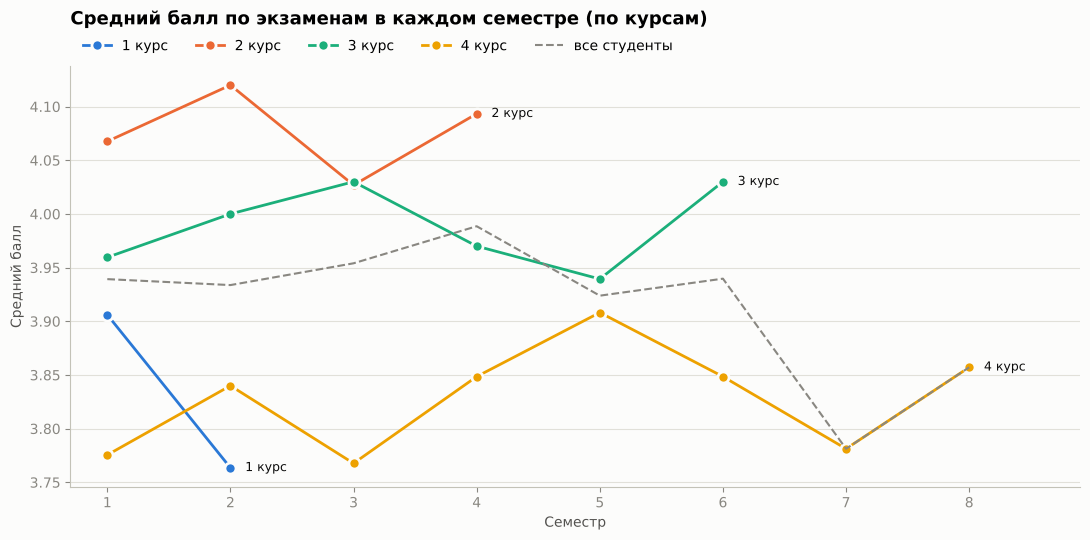

course,1,2,3,4
semester,,,,
1,3.91,4.07,3.96,3.78
2,3.76,4.12,4.00,3.84
3,NaN,4.03,4.03,3.77
4,NaN,4.09,3.97,3.85
5,NaN,NaN,3.94,3.91
6,NaN,NaN,4.03,3.85
7,NaN,NaN,NaN,3.78
8,NaN,NaN,NaN,3.86


In [6]:
dyn = (ex.assign(g=ex.grade.astype(int))
         .groupby(["course", "semester"]).g.mean().reset_index())
fig, ax = plt.subplots(figsize=(11, 5.5))
palette = {1: BLUE, 2: ORANGE, 3: AQUA, 4: YELLOW}
for course, d in dyn.groupby("course"):
    ax.plot(d.semester, d.g, color=palette[course], lw=2, marker="o", ms=8,
            markeredgecolor="#fcfcfb", markeredgewidth=2, label=f"{course} курс")
    ax.text(d.semester.iloc[-1] + 0.12, d.g.iloc[-1], f"{course} курс", color=INK, va="center", fontsize=9)
overall = ex.assign(g=ex.grade.astype(int)).groupby("semester").g.mean()
ax.plot(overall.index, overall.values, color=MUTED, lw=1.5, ls="--", label="все студенты")
ax.set_xticks(range(1, 9)); ax.set_xlim(0.7, 8.9)
ax.set_xlabel("Семестр"); ax.set_ylabel("Средний балл")
ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=5)
ax.set_title("Средний балл по экзаменам в каждом семестре (по курсам)", pad=30)
plt.tight_layout(); plt.savefig("images/3_dynamics.png", dpi=120); plt.show()
dyn.pivot(index="semester", columns="course", values="g").round(2)

## 4. Формы контроля

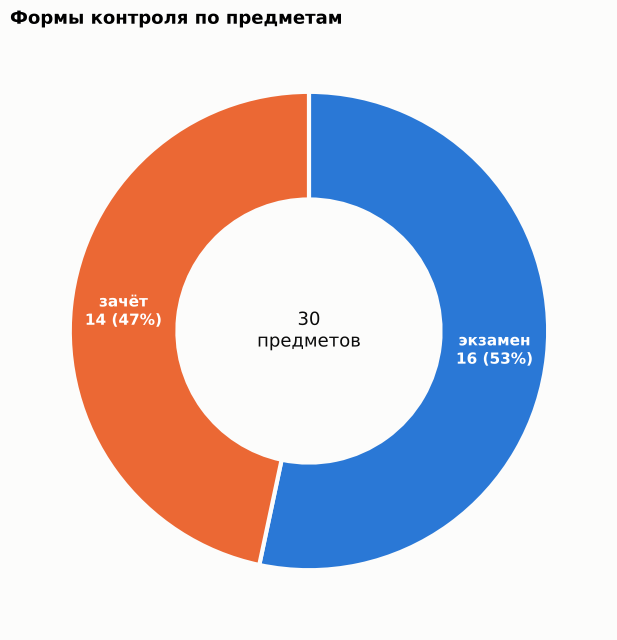

In [7]:
forms = subjects.control_form.value_counts()
fig, ax = plt.subplots(figsize=(6.5, 6.5))
wedges, _ = ax.pie(forms.values, colors=[BLUE, ORANGE][:len(forms)], startangle=90, counterclock=False,
                   wedgeprops={"edgecolor": "#fcfcfb", "linewidth": 3, "width": 0.45})
for w, (name, n) in zip(wedges, forms.items()):
    import numpy as np
    ang = np.deg2rad((w.theta1 + w.theta2) / 2)
    ax.text(0.78 * np.cos(ang), 0.78 * np.sin(ang), f"{name}\n{n} ({n / forms.sum():.0%})",
            ha="center", va="center", fontsize=11, color="white", fontweight="bold")
ax.text(0, 0, f"{forms.sum()}\nпредметов", ha="center", va="center", fontsize=13, color=INK)
ax.set_title("Формы контроля по предметам")
plt.tight_layout(); plt.savefig("images/4_control_forms.png", dpi=120); plt.show()

## Выводы
* Рейтинг показывает, кто из студентов группы проходит порог стипендии и у кого есть задолженности.
* По распределению оценок видно самые «трудные» предметы (больше двоек и троек) и зачёты с наибольшей долей незачётов.
* Динамика по семестрам показывает, как меняется средний балл каждого курса от семестра к семестру.
* Предметы учебного плана делятся на экзамены и зачёты примерно поровну.